# Exercise 1 — Predicting an unknown endpoint

Exercise sheet 1, practical work part II (a–c).

Full training consists of twelve full-batch runs.


Settings used and adapted from `SLT_Neural_Networks_Epsilon_Loss.ipynb`.

## Shared setup

Define reusable tools and configuration here. No networks are trained and no evaluation data are generated in this section.

### Imports and type aliases

Load the libraries and define the types used throughout the notebook. `FloatArray` describes NumPy arrays with floating-point entries; their shapes are documented separately.

In [ ]:
import time
from typing import TypeAlias, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from numpy.typing import NDArray

FloatArray: TypeAlias = NDArray[np.float64]
HiddenLayers: TypeAlias = tuple[int, ...]


### Shared settings

The input dimension N and the base data seed are used across tasks. Task-specific constants are defined at the beginning of II(a), II(b) and II(c).

In [ ]:
N: int = 10  # Observations per input vector.
DATA_SEED: int = 7  # Base seed from the course notebook.


### Plot appearance

Configure figure resolution, font size, borders and grid lines. These settings affect presentation only, not the calculations.

In [ ]:
# matplotlib settings (mainly taken from the example notebooks)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

print ("Settings configured!")


### Reproducible random streams

Create the common seed sequence. Each task allocates its own child seeds below; no data are generated here.

In [ ]:
seed_sequence: np.random.SeedSequence = np.random.SeedSequence(DATA_SEED)


### Shared functions

Define the helpers reused across tasks: `sample_examples()` generates sorted inputs and their labels; `mse()` measures prediction error; `baselines()` implements h1–h3; `theoretical_risks()` evaluates the formulas from Part I. These functions are only defined here, not called.

In [ ]:
def sample_examples(
    m: int, random_generator: np.random.Generator
) -> tuple[FloatArray, FloatArray]:
    """Generate examples for training or testing.

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: random generator for endpoints and observations.
    :return: Sorted inputs of shape (m, N) and endpoint labels of shape (m,).
        Each endpoint is drawn uniformly from [1, 5]. Conditional on that
        endpoint, the N observations are independent uniform draws from [0, L].
    """
    labels: FloatArray = random_generator.uniform(1.0, 5.0, m)
    uniform_samples: FloatArray = random_generator.uniform(size=(m, N))
    endpoints_column: FloatArray = labels.reshape(m, 1)
    inputs: FloatArray = uniform_samples * endpoints_column
    return np.sort(inputs, axis=1), labels


def mse(y: FloatArray, predictions: FloatArray) -> float:
    """Compute the empirical mean squared prediction error.

    :param y: One-dimensional NumPy array of true labels, shape (m,).
    :param predictions: One-dimensional NumPy array of predictions,
        with the same shape as y. No conversion or reshaping is performed.
    :return: Average squared difference as a float.
    :raises ValueError: If inputs are not one-dimensional, have different
        shapes, or contain no examples.
    """
    if y.ndim != 1 or y.shape != predictions.shape or y.size == 0:
        raise ValueError('Expected non-empty 1D arrays of the same shape.')
    return float(np.mean((y - predictions) ** 2))


def baselines(X: FloatArray) -> dict[str, FloatArray]:
    """Predict endpoints using the three rules specified in Task I.1.

    :param X: NumPy array of shape (m, N), one observation vector per row;
        sorting is not required. N is the global input size.
    :return: Dictionary mapping h1, h2 and h3 to predictions of shape
        (m,): twice the row mean, the row maximum, and (N + 1) / N
        times the row maximum, respectively.
    """
    maximum: FloatArray = X.max(axis=1)
    return {'h1': 2 * X.mean(axis=1), 'h2': maximum,
            'h3': ((N + 1) / N) * maximum}


def theoretical_risks(L_squared: float) -> dict[str, float]:
    """Evaluate the exact population risks derived in Part I.

    :param L_squared: L**2 for a fixed endpoint (Task I.1), or
        E[L**2] = 31/3 for L uniform on [1, 5] (Task I.2).
    :return: Dictionary of exact risks for h1, h2 and h3, using the
        global number N of observations per input vector.
    """
    return {'h1': L_squared / (3 * N),
            'h2': 2 * L_squared / ((N + 1) * (N + 2)),
            'h3': L_squared / (N * (N + 2))}


## II(a) — The endpoint population

Following Part I. 2, generate each example in two steps:

1. Draw the endpoint $L \sim \mathrm{Uniform}[1,5]$.
2. Given this $L$, draw $N = 10$ independent observations uniformly from $[0,L]$.

**Input:** the $N$ observations, sorted in ascending order.

**Target:** the endpoint $L$.

Repeat these steps independently to obtain $m = 10{,}000$ training examples, as required in Part II(a). All four architectures use the same training set.

### II(a) — Settings

Define the training size, prescribed architectures and common training settings. Allocate the training seed. These values are used only for training in II(a).

In [ ]:
N_TRAIN: int = 10_000
ARCHITECTURES: list[HiddenLayers] = [(16,), (64,), (32, 32), (64, 64, 32)]

# Common training settings from the course notebook.
EPOCHS: int = 4000
LEARNING_RATE: float = 0.003
INIT_SEEDS: list[int] = [11, 22, 33]
MAX_WORKERS: int = 3

training_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]


### II(a).1 — Generate the training data

Create the 10,000 training examples using the training seed. Display the first three examples. Each row of `X_train` corresponds to one label in `y_train`.

In [2]:
X_train: FloatArray
y_train: FloatArray
X_train, y_train = sample_examples(N_TRAIN, np.random.default_rng(training_stream))

print('Training:', X_train.shape, '| Label range:', y_train.min(), y_train.max())
display(pd.DataFrame(X_train[:3], columns=[f'u{i+1}' for i in range(N)])
        .assign(L=y_train[:3]).round(3))

Training: (10000, 10) | Label range: 1.000001149171522 4.999787752448674


,u1,u2,u3,u4,u5,u6,u7,u8,u9,u10,L
0,0.391,0.881,0.958,1.884,1.983,2.077,2.711,2.874,3.407,4.131,4.191
1,0.114,0.123,0.166,0.182,0.198,0.314,0.492,1.016,1.147,1.190,1.212
2,0.001,0.245,0.499,1.400,1.662,1.703,2.429,2.875,2.897,2.957,3.365


### II(a).2 — Define the network

Define a NumPy network with tanh hidden layers and a linear output. Its methods compute predictions, MSE gradients and parameter copies. This cell does not train a network.

**Source:** `SLT_Neural_Networks_Epsilon_Loss.ipynb`, Section 5, especially `Network.gradients()`.

**Important adaptation — not copied unchanged:** The course notebook trains with ε-insensitive loss and uses a subgradient of that loss. This notebook instead trains with MSE. This choice is an explicitly stated interpretation of the exercise's MSE objective, not a training setting explicitly specified on the sheet.

For MSE, the derivative with respect to prediction i is `2 * (prediction_i - label_i) / m`, where `m = len(X)` is the batch size. The factor 2 comes from differentiating the square; division by m comes from averaging. This derivative initializes `delta` in `gradients()`. Backpropagation then applies the chain rule to compute the weight and bias gradients used by Adam. The derivative has this sign even when MSE is written as `(label - prediction)**2`.

**Lecture reference:** VL 02, PDF page 9 defines MSE. The explicit MSE derivative above is derived from that definition; it is not stated directly in the four available lecture slide sets.

**Notation:** The code variable `delta` is a backpropagation quantity, not the uniform risk deviation Δ introduced in VL 03/04. With MSE we use ordinary gradients, not the ε-loss subgradient from the template.

In [ ]:
# NumPy network and Adam follow the course template; gradient adapted for MSE.
class Network:
    def __init__(self, hidden: HiddenLayers, seed: int) -> None:
        """Create the layers with random initial weights and zero biases."""
        rng: np.random.Generator = np.random.default_rng(seed)
        sizes: tuple[int, ...] = (N,) + tuple(hidden) + (1,)
        self.W: list[FloatArray] = [rng.normal(size=(a, b)) * np.sqrt(2 / (a + b))
                  for a, b in zip(sizes[:-1], sizes[1:])]
        self.b: list[FloatArray] = [np.zeros((1, b)) for b in sizes[1:]]

    def forward(self, X: FloatArray) -> list[FloatArray]:
        """Pass inputs through the network and return inputs and all layer outputs."""
        activations: list[FloatArray] = [X]
        for j, (W, b) in enumerate(zip(self.W, self.b)):
            z = activations[-1] @ W + b
            activations.append(np.tanh(z) if j < len(self.W) - 1 else z)
        return activations

    def predict(self, X: FloatArray) -> FloatArray:
        """Return one predicted endpoint L per input vector as a 1D array."""
        return self.forward(X)[-1].ravel()

    def gradients(self, X: FloatArray, y: FloatArray) -> list[FloatArray]:
        """Backpropagate the MSE to compute gradients for all weights and biases."""
        acts: list[FloatArray] = self.forward(X)
        # Adaptation of the course template: derivative of MSE, not ε-loss.
        delta: FloatArray = 2 * (acts[-1] - np.asarray(y).reshape(-1, 1)) / len(X)
        gW: list[FloatArray | None] = [None] * len(self.W)
        gb: list[FloatArray | None] = [None] * len(self.b)
        for j in reversed(range(len(self.W))):
            gW[j] = acts[j].T @ delta
            gb[j] = delta.sum(axis=0, keepdims=True)
            if j > 0:
                delta = (delta @ self.W[j].T) * (1 - acts[j] ** 2)
        # The loop fills every placeholder before returning.
        return cast(list[FloatArray], gW + gb)

    def copy_parameters(self) -> list[FloatArray]:
        """Copy the current weights and biases to save a training checkpoint."""
        return [p.copy() for p in self.W + self.b]

    def set_parameters(self, values: list[FloatArray]) -> None:
        """Restore the weights and biases from a saved parameter list."""
        for param, value in zip(self.W + self.b, values):
            param[:] = value


### II(a).3 — Define the training procedure

Define architecture labels and the full-batch Adam trainer. Each run uses the configured epoch budget and restores its best training checkpoint. The training procedure follows the course template, with the gradient adapted to MSE as mentioned previos. Training starts in a later cell.

In [ ]:
def architecture_name(hidden: HiddenLayers) -> str:
    """Build a readable architecture label including the input and output layers."""
    return ' → '.join(map(str, (N,) + tuple(hidden) + (1,)))

TrainingResult: TypeAlias = tuple[Network, float, int, FloatArray]

def train(hidden: HiddenLayers, seed: int) -> TrainingResult:
    """Train with full-batch Adam and return the best model, MSE, epoch and history."""
    net: Network = Network(hidden, seed)
    params: list[FloatArray] = net.W + net.b
    moment: list[FloatArray] = [np.zeros_like(p) for p in params]
    variance: list[FloatArray] = [np.zeros_like(p) for p in params]
    best_loss: float = np.inf
    best_parameters: list[FloatArray] | None = None
    best_epoch: int = 0
    history: list[tuple[int, float]] = []
    for epoch in range(1, EPOCHS + 1):
        gradients = net.gradients(X_train, y_train)
        for j, (param, grad) in enumerate(zip(params, gradients)):
            moment[j] = 0.9 * moment[j] + 0.1 * grad
            variance[j] = 0.999 * variance[j] + 0.001 * grad ** 2
            param -= LEARNING_RATE * (moment[j] / (1 - 0.9 ** epoch)) / (
                np.sqrt(variance[j] / (1 - 0.999 ** epoch)) + 1e-8)
        # Retain the best TRAINING iterate. Validation never enters this choice.
        loss = mse(y_train, net.predict(X_train))
        if loss < best_loss:
            best_loss, best_parameters, best_epoch = loss, net.copy_parameters(), epoch
        if epoch == 1 or epoch % 100 == 0 or epoch == EPOCHS:
            history.append((epoch, loss))
    # Positive EPOCHS and finite losses ensure a checkpoint was saved.
    net.set_parameters(cast(list[FloatArray], best_parameters))
    return net, best_loss, best_epoch, np.asarray(history)


### II(a).4 — Train the four architectures

Run each prescribed architecture with all three initialization seeds. For each architecture, retain the initialization with the lowest training MSE. Test data are not used for selection.

Unlike the course notebook, this cell uses a `ThreadPoolExecutor` to run up to `MAX_WORKERS` independent training runs in parallel.

In [4]:
from concurrent.futures import ThreadPoolExecutor, as_completed

# Parallelize independent runs only; batch size and epoch count are unchanged.
# Set to 1 if memory is limited or the CPU is slow.
models: dict[str, Network] = {}
histories: dict[str, FloatArray] = {}
runs: list[dict[str, str | int | float]] = []
selected_runs: dict[str, dict[str, int]] = {}
trials: dict[tuple[HiddenLayers, int], TrainingResult] = {}
started: float = time.perf_counter()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    # Run all architecture/seed combinations; submit larger networks first.
    jobs = {pool.submit(train, hidden, seed): (hidden, seed)
            for hidden in reversed(ARCHITECTURES) for seed in INIT_SEEDS}
    for job in as_completed(jobs):
        # Collect each result as soon as its independent training run finishes.
        hidden, seed = jobs[job]
        net, loss, best_epoch, history = job.result()
        trials[(hidden, seed)] = (net, loss, best_epoch, history)
        print(f'{architecture_name(hidden)}, Seed {seed}: Train-MSE {loss:.6f}', flush=True)
for hidden in ARCHITECTURES:
    name = architecture_name(hidden)
    for seed in INIT_SEEDS:
        net, loss, best_epoch, history = trials[(hidden, seed)]
        runs.append({'Model': name, 'Seed': seed, 'Train-MSE': loss,
                     'Best training epoch': best_epoch})
    seed = min(INIT_SEEDS, key=lambda s: trials[(hidden, s)][1])
    # Select by training MSE only; index 1 is the loss in TrainingResult.
    net, loss, best_epoch, history = trials[(hidden, seed)]
    models[name], histories[name] = net, history
    selected_runs[name] = {'Seed': seed, 'Epoch': best_epoch}
print(f'Training time: {(time.perf_counter() - started) / 60:.1f} min')
display(pd.DataFrame(runs).round(6))

10 → 64 → 64 → 32 → 1, Seed 33: Train-MSE 0.081209


10 → 64 → 64 → 32 → 1, Seed 22: Train-MSE 0.081340


10 → 64 → 64 → 32 → 1, Seed 11: Train-MSE 0.081264


10 → 32 → 32 → 1, Seed 11: Train-MSE 0.081592


10 → 32 → 32 → 1, Seed 22: Train-MSE 0.081487


...

10 → 16 → 1, Seed 11: Train-MSE 0.081995


10 → 16 → 1, Seed 22: Train-MSE 0.081993


10 → 16 → 1, Seed 33: Train-MSE 0.081961


Training time: 7.3 min


,Model,Seed,Train-MSE,Best training epoch
0,10 → 16 → 1,11,0.081995,4000
1,10 → 16 → 1,22,0.081993,4000
2,10 → 16 → 1,33,0.081961,4000
3,10 → 64 → 1,11,0.081731,4000
4,10 → 64 → 1,22,0.081637,4000
5,10 → 64 → 1,33,0.081791,4000
6,10 → 32 → 32 → 1,11,0.081592,4000
7,10 → 32 → 32 → 1,22,0.081487,4000
8,10 → 32 → 32 → 1,33,0.081573,4000
9,10 → 64 → 64 → 32 → 1,11,0.081264,4000


## II(b) — Training and independent testing

All seven rules are evaluated on the same 20,000 fresh test examples. 

Theory from I.2(b): ... **(to be added later)**. 

Standard errors refer to the test MSE conditional on the fitted networks, not to variation across new training runs.

### II(b) — Settings

Define the required test size and allocate a separate seed for the shared independent test set.

In [ ]:
N_TEST: int = 20_000
test_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]

# Replace None with population risks from I.2(b) if finished.
theory: dict[str, float | None] = {
    'h1': None,
    'h2': None,
    'h3': None,
}

### II(b).1 — Generate the test data

Create 20,000 fresh examples from Task I.2 using the independent test seed. Every fitted network and comparison rule will be evaluated on this same test set.

In [ ]:
X_test: FloatArray
y_test: FloatArray
X_test, y_test = sample_examples(N_TEST, np.random.default_rng(test_stream))

### II(b).2 — Compare training and test errors

Evaluate the four fitted networks and h1–h3. Display training MSE, test MSE, estimated test standard errors and any theoretical risks entered above (NaN means not yet provided). The networks remain unchanged.

**Optional addition (not required):** Test standard errors describe uncertainty from the independent test sample, assuming finite loss variance. They exclude training variability. We omit training standard errors because those data were used to fit the models. Error bars show ±2 standard errors, not guaranteed confidence bounds.

In [ ]:
train_predictions: dict[str, FloatArray] = {name: net.predict(X_train) for name, net in models.items()}
test_predictions: dict[str, FloatArray] = {name: net.predict(X_test) for name, net in models.items()}
train_predictions.update(baselines(X_train))
test_predictions.update(baselines(X_test))
rows: list[dict[str, str | float | np.float64]] = []
for name in train_predictions:
    losses = (test_predictions[name] - y_test) ** 2
    theory_value = theory.get(name)
    rows.append({'Model': name, 'Train-MSE': mse(y_train, train_predictions[name]),
                 'Test-MSE': losses.mean(), 'Test-SE': losses.std(ddof=1) / np.sqrt(N_TEST),
                 'Theory': theory_value if theory_value is not None else np.nan})
comparison: pd.DataFrame = pd.DataFrame(rows).set_index('Model')
display(comparison.round(6))

### II(b).3 — Plot the comparison

Plot training and test MSE side by side. Error bars show approximately two test standard errors; dashed lines are added only for theoretical risks you have entered.

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(comparison))
ax.bar(positions - 0.19, comparison['Train-MSE'], width=0.36, label='Training')
ax.bar(positions + 0.19, comparison['Test-MSE'], width=0.36, label='Test',
       yerr=2 * comparison['Test-SE'], capsize=3)
for i, name in enumerate(comparison.index):
    theory_value = theory.get(name)
    if theory_value is not None:
        ax.plot([i - 0.35, i + 0.35], [theory_value] * 2, color='black',
                linestyle='--', label=f'{name}: theory')
ax.set_xticks(positions, comparison.index, rotation=20, ha='right')
ax.set(ylabel='MSE', title='Shared data; error bars: ±2 test standard errors (approximate)')
ax.legend()
plt.tight_layout()
plt.show()

### II(b).4 — Compare simulation with theory

Compare test MSE with the theoretical risks entered in II(b) settings. Missing values are skipped; this comparison can be completed later.

In [ ]:
checks: list[dict[str, str | float | np.float64]] = []
for name, theory_value in theory.items():
    if theory_value is None:
        continue
    standard_error = comparison.loc[name, 'Test-SE']
    difference = comparison.loc[name, 'Test-MSE'] - theory_value
    checks.append({'Rule': name, 'Test minus theory': difference,
                   'Difference / Test-SE': difference / standard_error})
if checks:
    display(pd.DataFrame(checks).round(3))
else:
    print('Theory comparison pending: add the risks from I.2(b) in the II(b) settings.')


### II(b).5 — Summarize the results

Generate a short discussion using the computed table. Identifying the lowest observed test MSE describes this run; it does not trigger retraining or a new initialization choice.

In [ ]:
best_net = comparison.loc[list(models), 'Test-MSE'].idxmin()
best_baseline = comparison.loc[list(theory), 'Test-MSE'].idxmin()
train_gap = comparison.loc[best_net, 'Test-MSE'] - comparison.loc[best_net, 'Train-MSE']
lines: list[str] = [
    '### II(b) — Brief discussion',
    f'- In this run, **{best_net}** has the lowest test MSE among the networks '
    f'({comparison.loc[best_net, "Test-MSE"]:.5f}); among h1–h3, it is **{best_baseline}** '
    f'({comparison.loc[best_baseline, "Test-MSE"]:.5f}). This is a retrospective comparison, not test-based tuning.',
    f'- For this network, test MSE minus training MSE is **{train_gap:.5f}**. '
    'The tables allow a direct comparison of architectures; larger networks need not perform better under the same optimization budget.',
]
if all(value is not None for value in theory.values()):
    lines.append('- Compare the baseline test MSE with the theoretical risks in the table above.')
else:
    lines.append('- Theory comparison from I.2(b): to be completed after entering the missing risks.')
display(Markdown((chr(10) * 2).join(lines)))

## II(c) — Fixed L and distribution shift

For each L, generate 5,000 fresh input vectors and use the same vectors for all seven rules. The four trained networks remain unchanged. Dashed curves show the exact risks from I.1(b); the shaded region marks the training range [1,5].

### II(c) — Settings

Define the required endpoints and number of examples per endpoint. Allocate one separate seed for each fixed-L experiment.

In [ ]:
N_FIXED: int = 5_000
L_VALUES: FloatArray = np.array([0.5, 1, 2, 3, 4, 5, 6, 8])
fixed_streams: list[np.random.SeedSequence] = seed_sequence.spawn(len(L_VALUES))


### II(c).1 — Define the fixed-endpoint sampler

Unlike Task I.2, this sampler keeps L fixed. It generates sorted observation vectors from [0,L] and assigns the same known endpoint to every label. No examples are generated in this definition cell.

In [ ]:
def sample_fixed_endpoint(
    m: int, random_generator: np.random.Generator, fixed_L: float
) -> tuple[FloatArray, FloatArray]:
    """Generate fresh observation vectors for a fixed endpoint in Task II(c).

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: NumPy random generator for the observations.
    :param fixed_L: Positive endpoint shared by all examples.
    :return: Sorted inputs of shape (m, N) and labels of shape (m,),
        all equal to fixed_L. Each observation is drawn uniformly from [0, fixed_L].
    """
    labels: FloatArray = np.full(m, fixed_L, dtype=float)
    inputs: FloatArray = random_generator.uniform(size=(m, N)) * labels[:, None]
    return np.sort(inputs, axis=1), labels


### II(c).2 — Evaluate at each fixed endpoint

Generate 5,000 fresh examples per prescribed L and evaluate all seven rules on the same vectors. Record the errors and compare the baselines with theory. The trained networks remain unchanged.

In [ ]:
fixed_rows: list[dict[str, str | float | np.float64]] = []
X_fixed: FloatArray
y_fixed: FloatArray
for L, stream in zip(L_VALUES, fixed_streams):
    X_fixed, y_fixed = sample_fixed_endpoint(N_FIXED, np.random.default_rng(stream), fixed_L=L)
    predictions: dict[str, FloatArray] = {name: net.predict(X_fixed) for name, net in models.items()}
    predictions.update(baselines(X_fixed))
    exact = theoretical_risks(L ** 2)
    for name, pred in predictions.items():
        losses = (pred - y_fixed) ** 2
        fixed_rows.append({'L': L, 'Model': name, 'MSE': losses.mean(),
                           'SE': losses.std(ddof=1) / np.sqrt(N_FIXED),
                           'Theory': exact.get(name, np.nan)})
fixed_results: pd.DataFrame = pd.DataFrame(fixed_rows)
fixed_table: pd.DataFrame = fixed_results.pivot(index='L', columns='Model', values='MSE')
display(fixed_table.round(5))



Model,10 → 16 → 1,10 → 32 → 32 → 1,10 → 64 → 1,10 → 64 → 64 → 32 → 1,h1,h2,h3
L,,,,,,,
0.5,0.00352,0.05739,0.02193,0.18441,0.00815,0.00368,0.00203
1.0,0.01091,0.01282,0.01196,0.01334,0.03270,0.01471,0.00811
2.0,0.03735,0.03737,0.03762,0.03835,0.12936,0.06107,0.03380
3.0,0.08339,0.08544,0.08511,0.08380,0.30599,0.14516,0.07974
4.0,0.10877,0.10526,0.10402,0.10803,0.52086,0.24425,0.13336
5.0,0.19267,0.19120,0.19060,0.19085,0.82332,0.38426,0.21063
6.0,0.79682,0.69028,0.60290,0.79716,1.20417,0.55667,0.30536
8.0,5.53145,4.75515,3.77318,5.85162,2.12648,0.94447,0.52101


### II(c).3 — Plot errors against L

Show the fixed-endpoint results on linear and logarithmic MSE axes. Shade the training range [1,5] and overlay the theoretical risks of h1–h3.

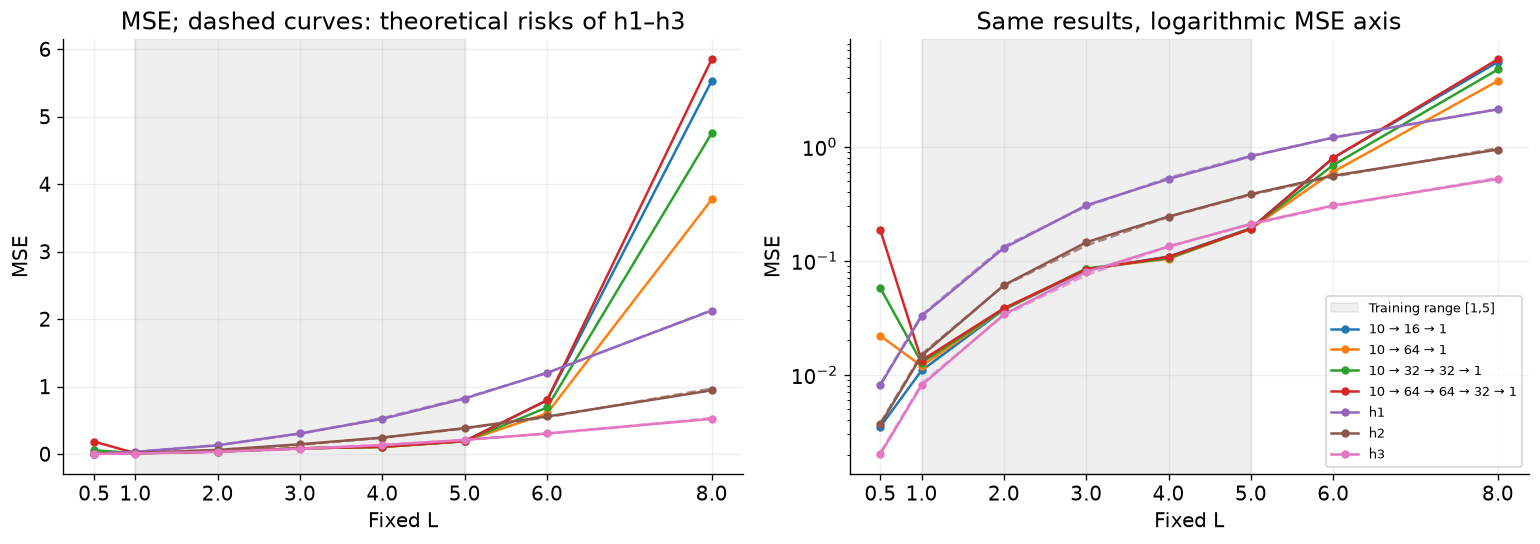

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for ax in axes:
    ax.axvspan(1, 5, color='grey', alpha=0.12, label='Training range [1,5]')
    for name in comparison.index:
        data = fixed_results[fixed_results.Model == name]
        line, = ax.plot(data.L, data.MSE, 'o-', label=name, markersize=4)
        if name in theory:
            ax.plot(data.L, data.Theory, '--', color=line.get_color(), alpha=0.7)
    ax.set(xlabel='Fixed L', ylabel='MSE', xticks=L_VALUES)
axes[0].set_title('MSE; dashed curves: theoretical risks of h1–h3')
axes[1].set_yscale('log')
axes[1].set_title('Same results, logarithmic MSE axis')
axes[1].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()


### II(c).4 — Discuss extrapolation

Summarize the behavior inside and outside [1,5], including the observed errors at L = 0.5, 6 and 8. This cell only reads previously computed results.

In [10]:
lines: list[str] = [
    '### II(c) — Brief discussion',
    '- For L = 1, 2, 3, 4, 5, the data-generating mechanism stays within the training range. '
    'Fixed-L errors need not be equal throughout that range.',
    '- L = 0.5, 6 and 8 lie outside the training distribution. '
    'The algebraic rules scale with L, so their theoretical L² risk scaling also holds there. '
    'The tanh networks do not have this scaling property and must extrapolate; good test performance on [1,5] does not guarantee good extrapolation.',
]
for L in [0.5, 6.0, 8.0]:
    row = fixed_table.loc[L]
    lines.append(f'- At L = {L:g}: MSE of {best_net} = **{row[best_net]:.5f}**, '
                 f'MSE of h3 = **{row["h3"]:.5f}**.')
lines.append('**Submission:** Review the tables, plots and this brief discussion; include the main results '
             'together with `theorie.md` in the required theory/discussion PDF. '
             'Submit the executable notebook separately as an `.ipynb` file.')
display(Markdown((chr(10) * 2).join(lines)))

### II(c) — Brief discussion

- For L = 1, 2, 3, 4, 5, the data-generating mechanism stays within the training range. Fixed-L errors need not be equal throughout that range.

- L = 0.5, 6 and 8 lie outside the training distribution. The algebraic rules scale with L, so their theoretical L² risk scaling also holds there. The tanh networks do not have this scaling property and must extrapolate; good test performance on [1,5] does not guarantee good extrapolation.

- At L = 0.5: MSE of 10 → 64 → 64 → 32 → 1 = **0.18441**, MSE of h3 = **0.00203**.

- At L = 6: MSE of 10 → 64 → 64 → 32 → 1 = **0.79716**, MSE of h3 = **0.30536**.

- At L = 8: MSE of 10 → 64 → 64 → 32 → 1 = **5.85162**, MSE of h3 = **0.52101**.

**Submission:** Review the tables, plots and this brief discussion; include the main results together with `theorie.md` in the required theory/discussion PDF. Submit the executable notebook separately as an `.ipynb` file.